# Validação Física: Ar Sujo, DRS, Incidentes e Safety Car — ApexSim

Este notebook valida os efeitos aerodinâmicos e estocásticos (`sim/physics.py` e `sim/events.py`) sobre os três circuitos do projeto (`Interlagos`, `Monza`, `Mônaco`).

**Glossário rápido:**
- **Área de escape (`runoff`)**: superfície fora da curva anotada nos mapas de pista (`asfalto`, `brita` ou `muro`). Determina se um carro que escapa consegue voltar sozinho (perda de tempo ou VSC) ou fica preso/bate (Safety Car).


In [1]:
%matplotlib inline
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np

backend_dir = Path("../../backend").resolve()
if str(backend_dir) not in sys.path:
    sys.path.insert(0, str(backend_dir))

from app.models.track import TrackMap
from sim.events import (
    SafetyCarStateMachine,
    build_track_risk_profile,
    sample_driver_lap_incident,
)
from sim.physics import dirty_air_time_delta, drs_lap_time_gain

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

interlagos = TrackMap.load(Path("../../track_maps/interlagos.json"))
monza = TrackMap.load(Path("../../track_maps/monza.json"))
monaco = TrackMap.load(Path("../../track_maps/monaco.json"))
print("Circuitos carregados:", interlagos.circuit_id, monza.circuit_id, monaco.circuit_id)


Circuitos carregados: interlagos monza monaco


## 1. Penalidade de Ar Sujo e Ganho de Tempo com DRS

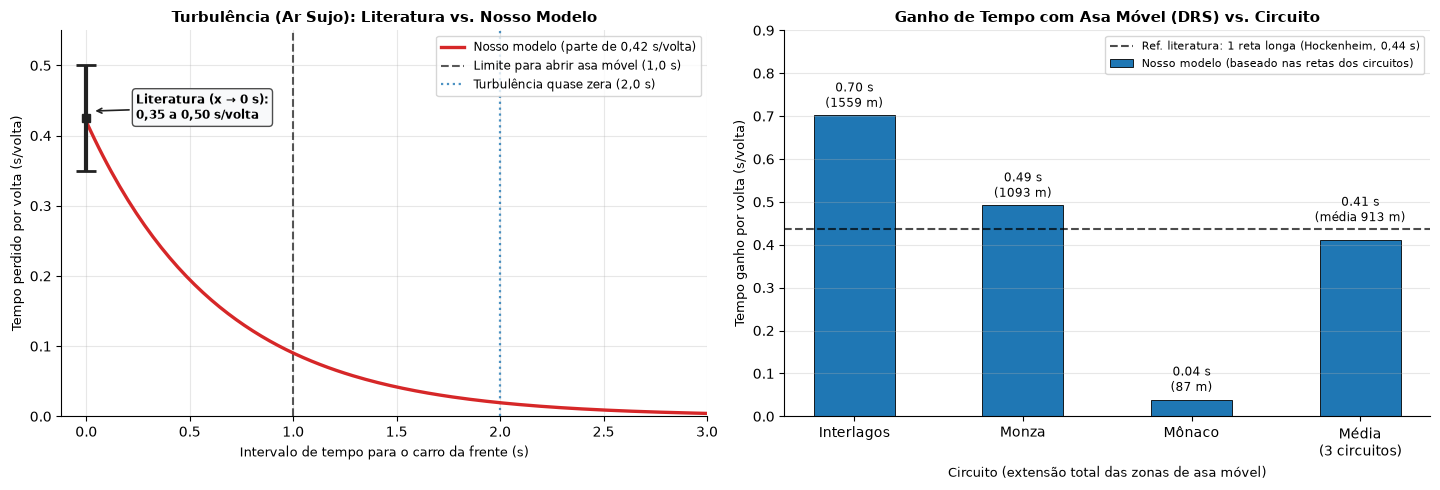

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.0))

gaps = np.linspace(0.0, 3.0, 150)
penalties = [dirty_air_time_delta(float(g)) for g in gaps]

# Barra de incerteza da literatura exatamente em x = 0 s, com caixinha ao lado
ax1.errorbar(
    [0.0],
    [0.425],
    yerr=[[0.075], [0.075]],
    fmt="s",
    color="#222222",
    ecolor="#222222",
    elinewidth=3.0,
    capsize=7,
    capthick=2.0,
    markersize=6,
    zorder=5,
)
ax1.annotate(
    "Literatura (x → 0 s):\n0,35 a 0,50 s/volta",
    xy=(0.03, 0.435),
    xytext=(0.24, 0.44),
    fontsize=8.6,
    fontweight="bold",
    va="center",
    bbox=dict(boxstyle="round,pad=0.3", fc="#f8f9fa", ec="#444444", lw=1.0, alpha=0.95),
    arrowprops=dict(arrowstyle="->", color="#222222", lw=1.2),
    zorder=6,
)
ax1.plot(gaps, penalties, color="tab:red", lw=2.4, zorder=4, label="Nosso modelo (parte de 0,42 s/volta)")
ax1.axvline(1.0, color="black", ls="--", alpha=0.65, label="Limite para abrir asa móvel (1,0 s)")
ax1.axvline(2.0, color="tab:blue", ls=":", lw=1.6, alpha=0.8, label="Turbulência quase zera (2,0 s)")
ax1.set_title("Turbulência (Ar Sujo): Literatura vs. Nosso Modelo", fontsize=11, fontweight="bold")
ax1.set_xlabel("Intervalo de tempo para o carro da frente (s)", fontsize=9.5)
ax1.set_ylabel("Tempo perdido por volta (s/volta)", fontsize=9.5)
ax1.set_xlim(-0.12, 3.0)
ax1.set_ylim(0, 0.55)
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8.4, loc="upper right", frameon=True)

tracks = [("Interlagos", interlagos), ("Monza", monza), ("Mônaco", monaco)]
names = [t[0] for t in tracks] + ["Média\n(3 circuitos)"]
drs_lengths = [sum(z.length_m for z in t[1].zones if z.type == "drs_activation") for t in tracks]
drs_gains = [drs_lap_time_gain(t[1], gap_ahead_s=0.6, current_lap=10) for t in tracks]
drs_lengths.append(float(np.mean(drs_lengths)))
drs_gains.append(float(np.mean(drs_gains)))

bars = ax2.bar(
    names,
    drs_gains,
    color="tab:blue",
    width=0.48,
    edgecolor="black",
    linewidth=0.6,
    label="Nosso modelo (baseado nas retas dos circuitos)",
)
ax2.axhline(0.436, color="black", ls="--", alpha=0.7, label="Ref. literatura: 1 reta longa (Hockenheim, 0,44 s)")
for idx, (bar, length_m, gain_s) in enumerate(zip(bars, drs_lengths, drs_gains)):
    sub = f"média {length_m:.0f} m" if idx == 3 else f"{length_m:.0f} m"
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        (0.455 if idx == 3 else gain_s + 0.02),
        f"{gain_s:.2f} s\n({sub})",
        ha="center",
        fontsize=8.8,
    )
ax2.set_ylim(0, 0.90)
ax2.set_title("Ganho de Tempo com Asa Móvel (DRS) vs. Circuito", fontsize=11, fontweight="bold")
ax2.set_xlabel("Circuito (extensão total das zonas de asa móvel)", fontsize=9.5)
ax2.set_ylabel("Tempo ganho por volta (s/volta)", fontsize=9.5)
ax2.grid(axis="y", alpha=0.3)
ax2.legend(fontsize=8.2, loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("validacao_ar_sujo_drs.png", dpi=130, bbox_inches="tight")
plt.show()


## 2. Frequência de Safety Car: Nossa Simulação vs. F1 Real (2022)

**Pergunta que este gráfico responde:** *Quantos Safety Cars (SC) e Safety Cars Virtuais (VSC) nosso modelo gera por corrida em comparação com a média real da temporada 2022 da F1?*

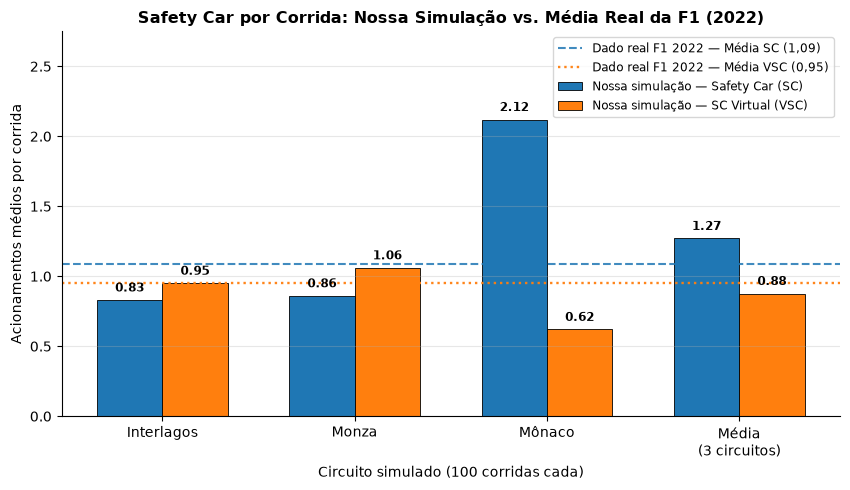

In [3]:
n_races = 100
n_laps = 58
n_drivers = 20

def simulate_100_races(track: TrackMap, seed: int = 2024):
    r = random.Random(seed)
    incidents, sc_list, vsc_list = [], [], []
    for _ in range(n_races):
        sm = SafetyCarStateMachine()
        for lap in range(1, n_laps + 1):
            lap_incs = []
            if sm.state == "GREEN":
                for d in range(n_drivers):
                    inc = sample_driver_lap_incident(
                        f"D{d:02d}", lap, track, r, grip_factor=0.88, weather="seco", aggression=0.5
                    )
                    if inc is not None:
                        incidents.append(inc)
                        lap_incs.append(inc)
            sm.trigger_from_incidents(lap_incs, r)
            sm.advance_lap()
        sc_list.append(sm.sc_deployments)
        vsc_list.append(sm.vsc_deployments)
    return incidents, sc_list, vsc_list

inc_inter, sc_inter, vsc_inter = simulate_100_races(interlagos, 2024)
inc_monza, sc_monza, vsc_monza = simulate_100_races(monza, 2025)
inc_monaco, sc_monaco, vsc_monaco = simulate_100_races(monaco, 2026)

braking_ratio = sum(1 for i in inc_inter if i.is_braking_zone) / len(inc_inter)

fig, ax_sc = plt.subplots(figsize=(8.6, 5.0))

labels = ["Interlagos", "Monza", "Mônaco", "Média\n(3 circuitos)"]
sc_means = [np.mean(sc_inter), np.mean(sc_monza), np.mean(sc_monaco), np.mean([sc_inter, sc_monza, sc_monaco])]
vsc_means = [np.mean(vsc_inter), np.mean(vsc_monza), np.mean(vsc_monaco), np.mean([vsc_inter, vsc_monza, vsc_monaco])]

x = np.arange(len(labels))
width = 0.34

bars_sc = ax_sc.bar(x - width / 2, sc_means, width, color="tab:blue", edgecolor="black", linewidth=0.6, label="Nossa simulação — Safety Car (SC)")
bars_vsc = ax_sc.bar(x + width / 2, vsc_means, width, color="tab:orange", edgecolor="black", linewidth=0.6, label="Nossa simulação — SC Virtual (VSC)")

for bar in list(bars_sc) + list(bars_vsc):
    h = bar.get_height()
    ax_sc.text(bar.get_x() + bar.get_width() / 2, h + 0.04, f"{h:.2f}", ha="center", va="bottom", fontsize=8.8, fontweight="bold")

ax_sc.axhline(24 / 22, color="tab:blue", ls="--", lw=1.5, alpha=0.85, label="Dado real F1 2022 — Média SC (1,09)")
ax_sc.axhline(21 / 22, color="tab:orange", ls=":", lw=1.7, alpha=0.95, label="Dado real F1 2022 — Média VSC (0,95)")

ax_sc.set_xticks(x)
ax_sc.set_xticklabels(labels, fontsize=10)
ax_sc.set_xlabel("Circuito simulado (100 corridas cada)", fontsize=9.8)
ax_sc.set_ylabel("Acionamentos médios por corrida", fontsize=9.8)
ax_sc.set_title("Safety Car por Corrida: Nossa Simulação vs. Média Real da F1 (2022)", fontsize=11.5, fontweight="bold")
ax_sc.set_ylim(0, 2.75)
ax_sc.grid(axis="y", alpha=0.3)
ax_sc.legend(fontsize=8.8, loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("validacao_acidentes_sc.png", dpi=130, bbox_inches="tight")
plt.show()


## 3. Onde Ocorrem os Incidentes na Pista? — Mapa 2D de Interlagos

**Pergunta que este gráfico responde:** *Em quais partes do traçado de Interlagos os acidentes se concentram na nossa simulação?* (~68% ocorrem nas entradas das 5 curvas de freada forte).

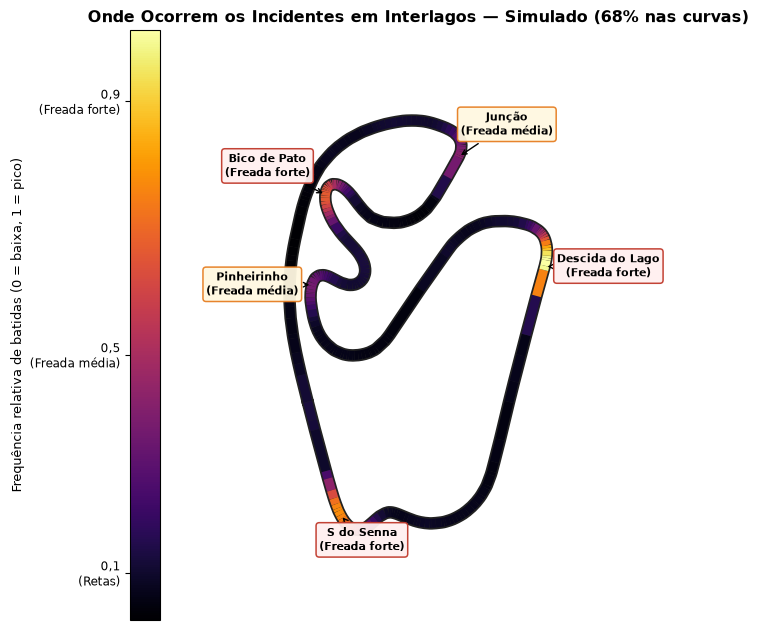

In [4]:
pts = interlagos.points
px = np.array([p["x"] for p in pts])
py = np.array([p["y"] for p in pts])
pd = np.array([p["distance_m"] for p in pts])

px_loop = np.append(px, px[0])
py_loop = np.append(py, py[0])
pd_loop = np.append(pd, float(interlagos.length_m))

def interp_xy(d_arr):
    return np.interp(d_arr, pd_loop, px_loop), np.interp(d_arr, pd_loop, py_loop)

seg_mid_d = 0.5 * (pd_loop[:-1] + pd_loop[1:])
inc_d = np.array([i.distance_m for i in inc_inter])
diff = np.abs(seg_mid_d[:, None] - inc_d[None, :])
diff = np.minimum(diff, interlagos.length_m - diff)
density = np.sum(np.exp(-0.5 * (diff / 45.0) ** 2), axis=1)
density_norm = density / density.max()

points_2d = np.array([px_loop, py_loop]).T.reshape(-1, 1, 2)
segments_2d = np.concatenate([points_2d[:-1], points_2d[1:]], axis=1)

fig, ax_heat = plt.subplots(figsize=(8.6, 6.4))

ax_heat.plot(px_loop, py_loop, color="#222222", lw=9, solid_capstyle="round", zorder=1)
lc = LineCollection(segments_2d, cmap="inferno", norm=plt.Normalize(0.0, 1.0), lw=6.5, zorder=2)
lc.set_array(density_norm)
ax_heat.add_collection(lc)
cbar = fig.colorbar(lc, ax=ax_heat, location="left", fraction=0.045, pad=0.03)
cbar.set_label("Frequência relativa de batidas (0 = baixa, 1 = pico)", fontsize=9.5)
cbar.set_ticks([0.08, 0.45, 0.88])
cbar.set_ticklabels(["0,1\n(Retas)", "0,5\n(Freada média)", "0,9\n(Freada forte)"], fontsize=8.5)

offsets = {
    "S do Senna": (55, -90),
    "Descida do Lago": (165, -25),
    "Pinheirinho": (-155, -25),
    "Bico de Pato": (-150, 48),
    "Junção": (125, 58),
}
for seg in build_track_risk_profile(interlagos):
    if seg.is_braking_zone and seg.corner_name:
        mid_d = 0.5 * (seg.start_m + seg.end_m)
        cx, cy = interp_xy(mid_d)
        dx, dy = offsets.get(seg.corner_name, (50, 30))
        if seg.severity == "alta":
            sub_txt = "Freada forte"
            fc_box, ec_box = "#fff0f0", "#c0392b"
        else:
            sub_txt = "Freada média"
            fc_box, ec_box = "#fff8e1", "#e67e22"
        ax_heat.annotate(
            f"{seg.corner_name}\n({sub_txt})",
            xy=(cx, cy),
            xytext=(cx + dx, cy + dy),
            fontsize=8.2,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.28", fc=fc_box, ec=ec_box, lw=1.1, alpha=0.95),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
            ha="center",
            zorder=5,
        )

ax_heat.set_title(f"Onde Ocorrem os Incidentes em Interlagos — Simulado ({braking_ratio:.0%} nas curvas)", fontsize=11.5, fontweight="bold")
ax_heat.set_aspect("equal")
ax_heat.margins(x=0.42, y=0.22)
ax_heat.axis("off")

plt.tight_layout()
plt.savefig("validacao_mapa_calor_pista.png", dpi=130, bbox_inches="tight")
plt.show()


## 4. Desfecho Após um Incidente vs. Área de Escape (300 Corridas)

Distribuição percentual do desfecho após ocorrer um incidente (`Sem SC/VSC`, `VSC` ou `Safety Car`), agrupada pelo tipo de área de escape (`Asfalto`, `Brita`, `Muro`).

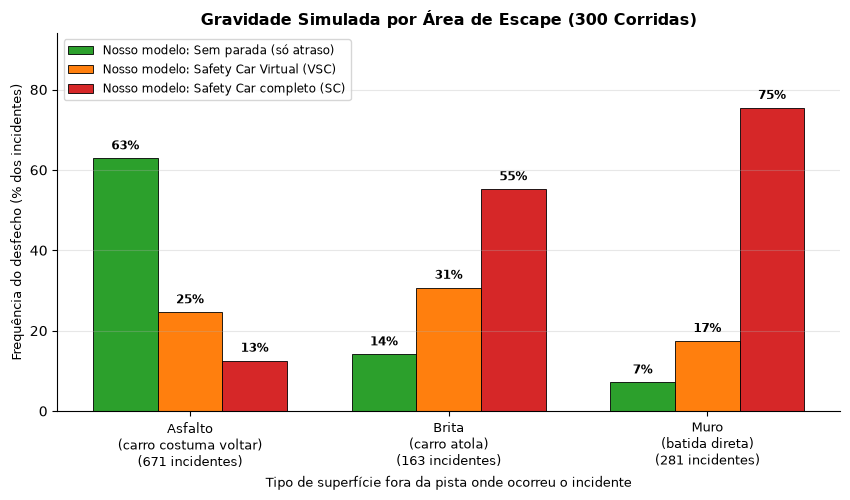

In [5]:
all_incs = inc_inter + inc_monza + inc_monaco
runoff_types = ["asfalto", "brita", "muro"]
runoff_labels = ["Asfalto\n(carro costuma voltar)", "Brita\n(carro atola)", "Muro\n(batida direta)"]
outcomes = [
    ("TIME_LOSS", "Nosso modelo: Sem parada (só atraso)", "tab:green"),
    ("VSC", "Nosso modelo: Safety Car Virtual (VSC)", "tab:orange"),
    ("SC", "Nosso modelo: Safety Car completo (SC)", "tab:red"),
]

fig, ax_runoff = plt.subplots(figsize=(8.6, 5.1))
x_r = np.arange(len(runoff_types))
width = 0.25

for i, (cons_key, cons_label, col) in enumerate(outcomes):
    pcts = []
    for r_type in runoff_types:
        sub = [inc for inc in all_incs if inc.runoff == r_type]
        pct = 100.0 * sum(1 for inc in sub if inc.consequence == cons_key) / len(sub)
        pcts.append(pct)
    offset = (i - 1) * width
    bars = ax_runoff.bar(
        x_r + offset,
        pcts,
        width,
        label=cons_label,
        color=col,
        edgecolor="black",
        linewidth=0.6,
    )
    for b, pct in zip(bars, pcts):
        ax_runoff.text(
            b.get_x() + b.get_width() / 2,
            pct + 1.5,
            f"{pct:.0f}%",
            ha="center",
            va="bottom",
            fontsize=8.8,
            fontweight="bold",
        )

counts_by_runoff = [sum(1 for inc in all_incs if inc.runoff == r_type) for r_type in runoff_types]
ax_runoff.set_xticks(x_r)
ax_runoff.set_xticklabels([f"{lbl}\n({n} incidentes)" for lbl, n in zip(runoff_labels, counts_by_runoff)], fontsize=9.0)
ax_runoff.set_xlabel("Tipo de superfície fora da pista onde ocorreu o incidente", fontsize=9.5)
ax_runoff.set_ylabel("Frequência do desfecho (% dos incidentes)", fontsize=9.5)
ax_runoff.set_title("Gravidade Simulada por Área de Escape (300 Corridas)", fontsize=11.5, fontweight="bold")
ax_runoff.set_ylim(0, 94)
ax_runoff.grid(axis="y", alpha=0.3)
ax_runoff.legend(loc="upper left", fontsize=8.8, frameon=True)

plt.tight_layout()
plt.savefig("validacao_desfecho_area_escape.png", dpi=130, bbox_inches="tight")
plt.show()
